# Data Understanding

## TopicSense NLP
### Supervised Multi-Class Text Classification

**CRISP-DM phase:** Data Understanding  
**Dataset:** 20 Newsgroups  
**Task:** Supervised multi-class text classification  
**Documents:** 18,846  
**Target classes:** 20  
**Primary evaluation metric:** Macro F1-score

---

## Introduction

This notebook examines the 20 Newsgroups dataset to establish its suitability for supervised multi-class text classification.

The objective is to understand the dataset's structure, quality, class distribution, document characteristics and potential sources of information leakage before implementing the data preparation and modelling workflows.

The analysis focuses on identifying characteristics that may influence model development, evaluation validity and the generalisability of classification results. Particular attention is given to the dataset's original message structure, including email headers, quoted correspondence and other metadata.

The original acquired documents are preserved throughout this phase. No text cleaning, token removal, stemming, lemmatisation or feature engineering is performed.

### Analytical objectives

- Examine the dataset structure, schema and provenance.
- Assess data completeness and record integrity.
- Investigate duplicate documents and potential train–test overlap.
- Analyse target-class distribution and imbalance.
- Examine document length and textual characteristics.
- Investigate message headers, quoted correspondence and metadata.
- Identify potential sources of target leakage and shortcut learning.
- Establish evidence-based requirements for data preparation.

## Analytical approach

The investigation combines descriptive statistics, data-quality validation, distributional analysis and targeted inspection of document content.

The original training and test partitions are retained. They are examined separately where appropriate, without combining their records or modifying their contents.

The official test partition is used exclusively for descriptive investigation in this phase. It will not be used to select preprocessing configurations, models or hyperparameters. Those decisions will be based on training and validation data in subsequent phases.

The findings from this notebook provide the empirical basis for the data preparation strategy.

In [120]:
from pathlib import Path
import json
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.metrics import adjusted_mutual_info_score

RANDOM_SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start_path: Path) -> Path:
    """Find the project root by locating pyproject.toml."""
    for directory in (start_path, *start_path.parents):
        if (directory / "pyproject.toml").is_file():
            return directory

    raise FileNotFoundError(
        "Could not locate the TopicSense project root. "
        "Ensure the notebook is stored inside the repository."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "20newsgroups"

TRAIN_PATH = DATA_DIR / "train.jsonl"
TEST_PATH = DATA_DIR / "test.jsonl"
METADATA_PATH = DATA_DIR / "metadata.json"

for path in (TRAIN_PATH, TEST_PATH, METADATA_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Required dataset file not found: {path}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset directory: {DATA_DIR}")
print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Dataset directory: /home/nkululekocyrilcele/projects/topicsense-nlp/data/raw/20newsgroups
Python version: 3.12.3
NumPy version: 2.5.5
Pandas version: 3.1.1


## Dataset provenance and acquisition

The primary benchmark is the **20 Newsgroups** text dataset, acquired through scikit-learn's `fetch_20newsgroups` loader.

The dataset contains archived discussion messages assigned to 20 predefined newsgroup categories. It provides separate official training and test partitions, which are retained for this project.

During acquisition, the original document text was preserved. Headers, signatures, quoted messages and other embedded content were not removed. This is important because the presence of these elements must be investigated before decisions about text representation and preprocessing can be justified.

The acquired records are stored in JSON Lines format, with one document per record. Dataset metadata is stored separately to preserve information about the source, class labels and partition sizes.

The following analysis verifies the acquired data against the expected dataset structure and partition counts.

In [121]:
with TRAIN_PATH.open("r", encoding="utf-8") as file:
    train_data = pd.read_json(file, lines=True)

with TEST_PATH.open("r", encoding="utf-8") as file:
    test_data = pd.read_json(file, lines=True)

with METADATA_PATH.open("r", encoding="utf-8") as file:
    dataset_metadata = json.load(file)

print("Training partition:")
display(train_data.head(3))

print("\nTest partition:")
display(test_data.head(3))

print("\nDataset metadata:")
display(pd.Series(dataset_metadata, dtype="object"))

Training partition:


,document_id,text,label,label_name,split
0,train_000000,From: cubbie@garnet.berkeley.edu ( )\nSubject: Re: Cubs behind Marlins? How?\nArticle-...,9,rec.sport.baseball,train
1,train_000001,From: gnelson@pion.rutgers.edu (Gregory Nelson)\nSubject: Thanks Apple: Free Ethernet on my C610!\nArticle-I.D.: pio...,4,comp.sys.mac.hardware,train
2,train_000002,From: crypt-comments@math.ncsu.edu\nSubject: Cryptography FAQ 10/10 - References\nOrganization: The Crypt Cabal\nLin...,11,sci.crypt,train



Test partition:


,document_id,text,label,label_name,split
0,test_000000,From: stimpy@dev-null.phys.psu.edu (Gregory Nagy)\nSubject: Re: ESPN UP YOURS .........\nOrganization: Penn State La...,10,rec.sport.hockey,test
1,test_000001,From: kennejs@a.cs.okstate.edu (KENNEDY JAMES SCOT)\nSubject: Re: Blast them next time\nOrganization: Oklahoma State...,16,talk.politics.guns,test
2,test_000002,From: perky@acs.bu.edu (Melissa Sherrin)\nSubject: Re: moon image in weather sat image\nOrganization: Boston Univers...,14,sci.space,test



Dataset metadata:


dataset                                                                                                                                       20 Newsgroups
source                                                                                                                      scikit-learn fetch_20newsgroups
source_url                                                          https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset
task_type                                                                                                                    multiclass_text_classification
number_of_classes                                                                                                                                        20
classes                             [alt.atheism, comp.graphics, comp.os.ms-windows.misc, comp.sys.ibm.pc.hardware, comp.sys.mac.hardware, comp.windows....
split_counts                                                    

In [122]:
datasets = {
    "Training": train_data,
    "Test": test_data,
}

overview = pd.DataFrame(
    {
        name: {
            "Documents": len(data),
            "Columns": len(data.columns),
            "Missing values": int(data.isna().sum().sum()),
            "Unique document IDs": data["document_id"].nunique(),
            "Unique classes": data["label"].nunique(),
        }
        for name, data in datasets.items()
    }
).T

display(overview)

,Documents,Columns,Missing values,Unique document IDs,Unique classes
Training,11314,5,0,11314,20
Test,7532,5,0,7532,20


### Initial dataset overview

The dataset contains 11,314 training documents and 7,532 test documents. Both partitions contain five fields, have no missing values, contain unique document identifiers and represent all 20 target classes.

The following checks examine these properties in greater detail rather than relying exclusively on the initial overview.

## Dataset structure and integrity

### Schema validation

The dataset is expected to contain five fields:

| Field | Description |
|---|---|
| `document_id` | Unique identifier assigned to each document |
| `text` | Original document content |
| `label` | Integer-encoded target class |
| `label_name` | Human-readable target category |
| `split` | Original dataset partition |

The schema, data types, missing values and expected columns are examined independently for the training and test partitions.

### Record-level integrity

Additional checks assess whether records satisfy the expected structural constraints. These include document identifier uniqueness, non-empty document content, valid target labels, correct partition assignments and consistency between numerical labels and their corresponding class names.

The acquired partition sizes are also compared against the expected counts reported by the dataset source.

These checks establish whether the dataset has been acquired and represented consistently before further analysis.

In [123]:
EXPECTED_COLUMNS = [
    "document_id",
    "text",
    "label",
    "label_name",
    "split",
]

for split_name, data in datasets.items():
    print(f"\n{split_name} partition")
    print("=" * 60)

    print("\nData types:")
    display(data.dtypes.rename("Data type").to_frame())

    print("\nMissing values by column:")
    missing_summary = pd.DataFrame({
        "Missing values": data.isna().sum(),
        "Missing percentage": (
            data.isna().mean() * 100
        ).round(3),
    })
    display(missing_summary)

    print("\nUnexpected columns:")
    print(sorted(set(data.columns) - set(EXPECTED_COLUMNS)))

    print("\nMissing expected columns:")
    print(sorted(set(EXPECTED_COLUMNS) - set(data.columns)))


Training partition

Data types:


,Data type
document_id,str
text,str
label,int64
label_name,str
split,str



Missing values by column:


,Missing values,Missing percentage
document_id,0,0.0
text,0,0.0
label,0,0.0
label_name,0,0.0
split,0,0.0



Unexpected columns:
[]

Missing expected columns:
[]

Test partition

Data types:


,Data type
document_id,str
text,str
label,int64
label_name,str
split,str



Missing values by column:


,Missing values,Missing percentage
document_id,0,0.0
text,0,0.0
label,0,0.0
label_name,0,0.0
split,0,0.0



Unexpected columns:
[]

Missing expected columns:
[]


In [124]:
integrity_results = []

expected_splits = {
    "Training": "train",
    "Test": "test",
}

for split_name, data in datasets.items():
    expected_split = expected_splits[split_name]

    results = {
        "Partition": split_name,
        "Rows": len(data),
        "Duplicate document IDs": int(
            data["document_id"].duplicated().sum()
        ),
        "Empty document IDs": int(
            data["document_id"].isna().sum()
        ),
        "Empty text documents": int(
            data["text"].str.strip().eq("").sum()
        ),
        "Invalid label values": int(
            (~data["label"].between(0, 19)).sum()
        ),
        "Unexpected split values": int(
            (~data["split"].eq(expected_split)).sum()
        ),
        "Label-name inconsistencies": int(
            (
                data["label_name"]
                != data["label"].map(
                    dict(enumerate(dataset_metadata["classes"]))
                )
            ).sum()
        ),
    }

    integrity_results.append(results)

integrity_summary = pd.DataFrame(integrity_results).set_index(
    "Partition"
)

display(integrity_summary)

,Rows,Duplicate document IDs,Empty document IDs,Empty text documents,Invalid label values,Unexpected split values,Label-name inconsistencies
Partition,,,,,,,
Training,11314,0,0,0,0,0,0
Test,7532,0,0,0,0,0,0


In [125]:
expected_counts = {
    "train": 11314,
    "test": 7532,
}

actual_counts = {
    "train": len(train_data),
    "test": len(test_data),
}

count_comparison = pd.DataFrame({
    "Expected documents": expected_counts,
    "Actual documents": actual_counts,
})

count_comparison["Difference"] = (
    count_comparison["Actual documents"]
    - count_comparison["Expected documents"]
)

display(count_comparison)

print(f"\nTotal documents: {sum(actual_counts.values()):,}")
print(f"Total classes: {len(dataset_metadata['classes'])}")

,Expected documents,Actual documents,Difference
train,11314,11314,0
test,7532,7532,0



Total documents: 18,846
Total classes: 20


### Structural validation findings

The acquired dataset contains 11,314 training documents and 7,532 test documents, giving a total of 18,846 documents across 20 target classes.

Both partitions contain the five expected fields. No missing values, unexpected columns, duplicate document identifiers, empty document identifiers, empty document texts, invalid target labels, incorrect partition assignments or inconsistencies between numerical labels and class names were detected.

The actual partition sizes also match the expected dataset counts.

These results indicate that the acquired dataset satisfies the structural and record-level integrity checks performed in this investigation. No corrective action is required for the identified data-quality issues.

The findings establish a reliable starting point for subsequent analysis. They do not, however, establish that the textual content is free from misleading metadata or other sources of classification shortcuts. These are investigated separately below.

## Duplicate-document analysis

Duplicate records can compromise the validity of supervised classification evaluation. In particular, identical documents appearing in both training and test partitions may allow a model to encounter previously observed content during evaluation.

The investigation distinguishes between:

- Repeated document text within the training partition.
- Repeated document text within the test partition.
- Exact document-text overlap between the two partitions.

Comparisons are performed using the original document text without normalisation or text cleaning.

This analysis detects exact textual duplicates. It does not identify near-duplicates, paraphrases or semantically similar documents.

In [126]:
train_texts = train_data["text"].fillna("")
test_texts = test_data["text"].fillna("")

train_duplicate_count = int(train_texts.duplicated().sum())
test_duplicate_count = int(test_texts.duplicated().sum())

train_unique_texts = set(train_texts)
test_unique_texts = set(test_texts)

cross_split_overlap = train_unique_texts.intersection(
    test_unique_texts
)

duplicate_summary = pd.DataFrame(
    {
        "Measure": [
            "Duplicate documents in training",
            "Duplicate documents in test",
            "Unique training documents",
            "Unique test documents",
            "Exact texts shared across partitions",
        ],
        "Count": [
            train_duplicate_count,
            test_duplicate_count,
            len(train_unique_texts),
            len(test_unique_texts),
            len(cross_split_overlap),
        ],
    }
)

display(duplicate_summary)

,Measure,Count
0,Duplicate documents in training,0
1,Duplicate documents in test,0
2,Unique training documents,11314
3,Unique test documents,7532
4,Exact texts shared across partitions,0


### Duplicate-document findings

No exact duplicate document texts were identified within either the training or test partition.

The training partition contains 11,314 unique document texts, while the test partition contains 7,532 unique document texts. No exact textual overlap was detected between the two partitions.

This result reduces the risk that evaluation performance will be inflated by identical documents appearing in both partitions.

The investigation is limited to exact textual equality. It does not establish the absence of near-duplicates, related discussion threads or semantically similar documents. Those possibilities are outside the scope of the current duplicate check.

## Target-class distribution

The classification task involves 20 predefined newsgroup categories. Examining their representation is important for understanding whether the dataset contains substantial class imbalance and whether the original training and test partitions have comparable class distributions.

The analysis examines:

- The number of documents assigned to each class.
- The relative frequency of each class within its partition.
- The minimum, maximum and mean class counts.
- The class imbalance ratio.
- Differences between the training and test class proportions.

Macro-averaged F1-score is selected as the primary evaluation metric. Unlike accuracy, macro-F1 calculates the F1-score independently for each class and gives each class equal weight in the final average.

This is appropriate for a multi-class task in which performance across all categories matters, rather than performance being dominated by the most frequently represented categories.

In [127]:
class_names = dataset_metadata["classes"]

train_counts = (
    train_data["label_name"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

test_counts = (
    test_data["label_name"]
    .value_counts()
    .reindex(class_names, fill_value=0)
)

class_distribution = pd.DataFrame({
    "Training": train_counts,
    "Test": test_counts,
})

class_distribution["Training (%)"] = (
    class_distribution["Training"]
    / len(train_data) * 100
)

class_distribution["Test (%)"] = (
    class_distribution["Test"]
    / len(test_data) * 100
)

display(
    class_distribution.round(2).sort_values(
        "Training",
        ascending=False,
    )
)

,Training,Test,Training (%),Test (%)
label_name,,,,
rec.sport.hockey,600,399,5.30,5.30
soc.religion.christian,599,398,5.29,5.28
rec.motorcycles,598,398,5.29,5.28
rec.sport.baseball,597,397,5.28,5.27
sci.crypt,595,396,5.26,5.26
rec.autos,594,396,5.25,5.26
sci.med,594,396,5.25,5.26
comp.windows.x,593,395,5.24,5.24
sci.space,593,394,5.24,5.23


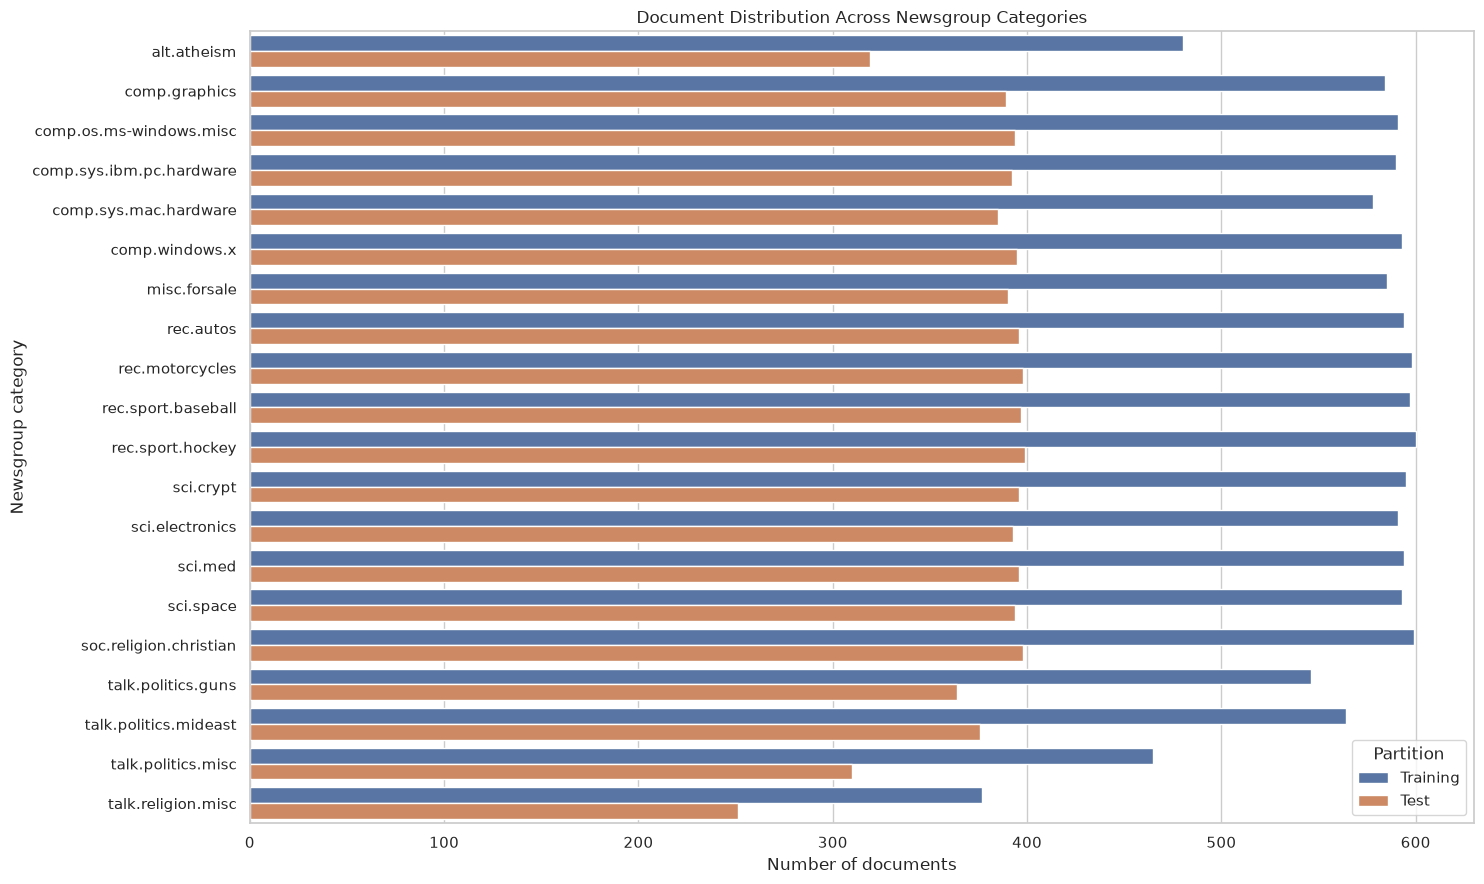

In [128]:
class_plot_data = (
    class_distribution[["Training", "Test"]]
    .reset_index(names="Class")
    .melt(
        id_vars="Class",
        var_name="Partition",
        value_name="Documents",
    )
)

plt.figure(figsize=(15, 9))

sns.barplot(
    data=class_plot_data,
    x="Documents",
    y="Class",
    hue="Partition",
)

plt.title("Document Distribution Across Newsgroup Categories")
plt.xlabel("Number of documents")
plt.ylabel("Newsgroup category")
plt.legend(title="Partition")
plt.tight_layout()
plt.show()

In [129]:
imbalance_summary = pd.DataFrame({
    "Partition": ["Training", "Test"],
    "Minimum class count": [
        train_counts.min(),
        test_counts.min(),
    ],
    "Maximum class count": [
        train_counts.max(),
        test_counts.max(),
    ],
    "Mean class count": [
        train_counts.mean(),
        test_counts.mean(),
    ],
    "Class imbalance ratio": [
        train_counts.max() / train_counts.min(),
        test_counts.max() / test_counts.min(),
    ],
})

display(imbalance_summary.round(3))

,Partition,Minimum class count,Maximum class count,Mean class count,Class imbalance ratio
0,Training,377,600,565.7,1.592
1,Test,251,399,376.6,1.590


In [130]:
distribution_comparison = pd.DataFrame({
    "Training (%)": (
        train_counts / len(train_data) * 100
    ),
    "Test (%)": (
        test_counts / len(test_data) * 100
    ),
})

distribution_comparison["Absolute Difference (pp)"] = (
    distribution_comparison["Training (%)"]
    - distribution_comparison["Test (%)"]
).abs()

display(
    distribution_comparison.sort_values(
        "Absolute Difference (pp)",
        ascending=False,
    ).round(3)
)

,Training (%),Test (%),Absolute Difference (pp)
label_name,,,
comp.sys.ibm.pc.hardware,5.215,5.204,0.010
sci.space,5.241,5.231,0.010
soc.religion.christian,5.294,5.284,0.010
rec.autos,5.250,5.258,0.007
sci.med,5.250,5.258,0.007
comp.os.ms-windows.misc,5.224,5.231,0.007
misc.forsale,5.171,5.178,0.007
alt.atheism,4.243,4.235,0.007
talk.politics.mideast,4.985,4.992,0.007


### Class distribution findings

All 20 target categories are represented in both official partitions.

The training class counts range from 377 to 600 documents, while the test class counts range from 251 to 399 documents. The resulting imbalance ratios are approximately 1.592 and 1.590, respectively.

These ratios indicate modest class imbalance rather than severe underrepresentation. The relative class proportions are also highly consistent between the two partitions, with the largest observed difference being approximately 0.01 percentage points.

The results do not provide a strong justification for resampling the original training data at this stage. Oversampling, undersampling and synthetic minority-class generation are therefore not introduced during Data Understanding.

Macro-F1 remains the primary evaluation metric because it gives equal importance to each target category. The original class distributions and official test partition will be preserved.

## Document length and textual characteristics

Document length can influence both classification performance and computational requirements. Short documents may provide limited contextual information, whereas very long documents may contain extensive quoted correspondence, embedded content or other material that increases processing costs.

The investigation uses two descriptive measurements:

- **Character count:** the number of characters in the original document.
- **Whitespace-separated word count:** the number of units obtained by splitting the document on whitespace.

Whitespace-separated word counts are descriptive approximations. They should not be interpreted as linguistic token counts or as estimates of the number of subword tokens produced by a transformer tokenizer.

The analysis compares document-length distributions across the training and test partitions and examines variation across target categories.

In [131]:
for data in datasets.values():
    data["character_count"] = data["text"].str.len()

    data["word_count"] = data["text"].str.split().str.len()

length_summary = pd.DataFrame({
    split_name: {
        "Mean characters": data["character_count"].mean(),
        "Median characters": data["character_count"].median(),
        "Minimum characters": data["character_count"].min(),
        "Maximum characters": data["character_count"].max(),
        "Mean words": data["word_count"].mean(),
        "Median words": data["word_count"].median(),
        "Minimum words": data["word_count"].min(),
        "Maximum words": data["word_count"].max(),
    }
    for split_name, data in datasets.items()
}).T

display(length_summary.round(2))

,Mean characters,Median characters,Minimum characters,Maximum characters,Mean words,Median words,Minimum words,Maximum words
Training,1949.31,1178.0,125.0,75154.0,287.47,176.0,14.0,11821.0
Test,1832.25,1168.5,115.0,160616.0,277.93,173.0,12.0,9578.0


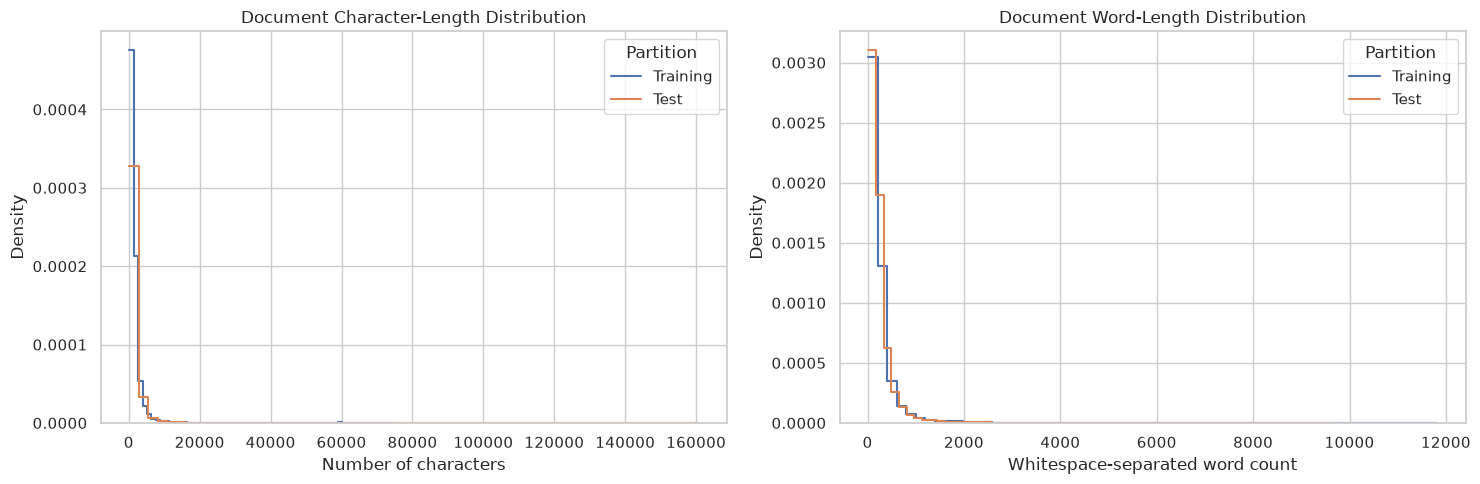

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for split_name, data in datasets.items():
    sns.histplot(
        data=data,
        x="character_count",
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=split_name,
        ax=axes[0],
    )

    sns.histplot(
        data=data,
        x="word_count",
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=split_name,
        ax=axes[1],
    )

axes[0].set_title("Document Character-Length Distribution")
axes[0].set_xlabel("Number of characters")
axes[0].set_ylabel("Density")
axes[0].legend(title="Partition")

axes[1].set_title("Document Word-Length Distribution")
axes[1].set_xlabel("Whitespace-separated word count")
axes[1].set_ylabel("Density")
axes[1].legend(title="Partition")

plt.tight_layout()
plt.show()

In [133]:
percentiles = [0.00, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]

percentile_results = []

for split_name, data in datasets.items():
    for measure in ("character_count", "word_count"):
        values = data[measure].quantile(percentiles)

        for percentile, value in values.items():
            percentile_results.append({
                "Partition": split_name,
                "Measure": measure,
                "Percentile": f"{percentile:.0%}",
                "Length": value,
            })

percentile_table = pd.DataFrame(percentile_results)

display(
    percentile_table.pivot_table(
        index=["Measure", "Percentile"],
        columns="Partition",
        values="Length",
    ).round(2)
)

Partition                        Test  Training
Measure         Percentile                     
character_count 0%             115.00    125.00
                10%            490.00    499.00
                100%        160616.00  75154.00
                25%            748.00    753.25
                50%           1168.50   1178.00
                75%           1861.00   1881.00
                90%           3147.00   3161.00
                95%           4502.15   4844.05
                99%          12463.83  14328.01
word_count      0%              12.00     14.00
                10%             69.00     69.00
                100%          9578.00  11821.00
                25%            107.00    108.00
                50%            173.00    176.00
                75%            292.00    293.00
                90%            501.00    508.00
                95%            732.00    772.00
                99%           1942.38   1956.00

In [134]:
for split_name, data in datasets.items():
    print(f"\n{split_name}: Shortest documents")
    display(
        data.nsmallest(5, "word_count")[
            ["document_id", "label_name", "character_count", "word_count"]
        ]
    )

    print(f"\n{split_name}: Longest documents")
    display(
        data.nlargest(5, "word_count")[
            ["document_id", "label_name", "character_count", "word_count"]
        ]
    )


Training: Shortest documents


,document_id,label_name,character_count,word_count
182,train_000182,comp.sys.mac.hardware,125,14
7299,train_007299,comp.windows.x,169,15
10389,train_010389,rec.autos,131,15
3871,train_003871,comp.graphics,245,16
4577,train_004577,comp.windows.x,163,16



Training: Longest documents


,document_id,label_name,character_count,word_count
7137,train_007137,sci.electronics,72637,11821
7833,train_007833,rec.sport.hockey,75154,11278
3412,train_003412,talk.politics.mideast,62187,11263
348,train_000348,talk.politics.mideast,56402,10365
1176,train_001176,comp.windows.x,66459,9523



Test: Shortest documents


,document_id,label_name,character_count,word_count
6627,test_006627,alt.atheism,115,12
1001,test_001001,comp.windows.x,145,14
5872,test_005872,comp.windows.x,129,14
7314,test_007314,comp.windows.x,147,14
5696,test_005696,comp.windows.x,287,15



Test: Longest documents


,document_id,label_name,character_count,word_count
3761,test_003761,talk.politics.mideast,53119,9578
5377,test_005377,comp.graphics,57725,9255
6519,test_006519,comp.graphics,57481,9225
5581,test_005581,sci.space,57022,9138
1493,test_001493,comp.windows.x,56625,8586


In [135]:
class_length_summary = (
    train_data.groupby("label_name")
    .agg(
        document_count=("document_id", "count"),
        mean_words=("word_count", "mean"),
        median_words=("word_count", "median"),
        min_words=("word_count", "min"),
        max_words=("word_count", "max"),
    )
    .sort_values("median_words", ascending=False)
)

display(class_length_summary.round(2))

,document_count,mean_words,median_words,min_words,max_words
label_name,,,,,
talk.politics.mideast,564,499.72,269.0,19,11263
soc.religion.christian,599,372.40,262.0,23,2976
talk.politics.misc,465,447.00,251.0,19,7989
talk.politics.guns,546,368.51,250.5,33,8452
sci.crypt,595,382.03,214.0,34,8943
alt.atheism,480,345.24,210.0,33,8648
talk.religion.misc,377,356.26,208.0,26,4767
rec.sport.hockey,600,305.41,184.5,17,11278
sci.space,593,300.03,181.0,20,6141


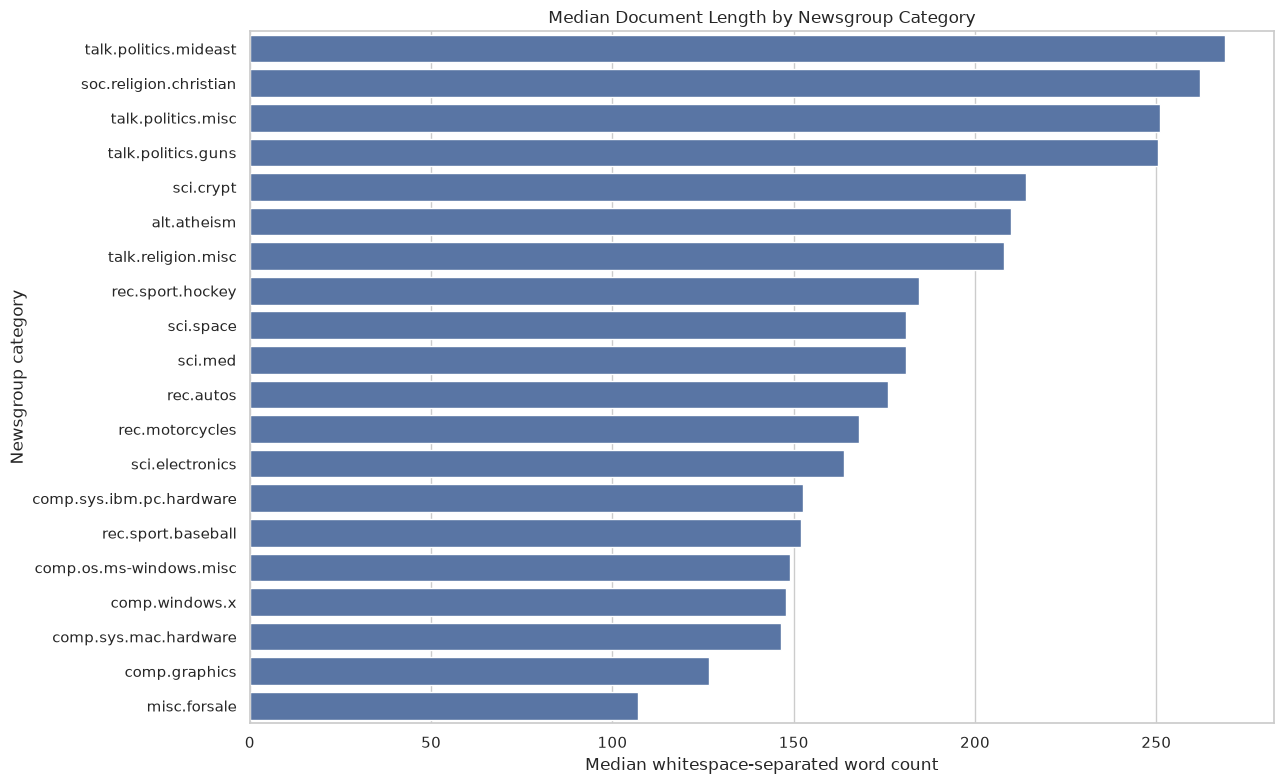

In [136]:
plt.figure(figsize=(13, 8))

sns.barplot(
    data=class_length_summary.reset_index(),
    x="median_words",
    y="label_name",
)

plt.title("Median Document Length by Newsgroup Category")
plt.xlabel("Median whitespace-separated word count")
plt.ylabel("Newsgroup category")
plt.tight_layout()
plt.show()

### Document-length findings

The document-length distributions are strongly right-skewed. Most documents are relatively short, but a small number contain substantially more text than the typical record.

The median document lengths are comparable across the two partitions: 1,178 characters and 176 whitespace-separated words for training, compared with 1,168.5 characters and 173 words for testing. The corresponding 99th-percentile word counts are approximately 1,956 and 1,942.

The maximum document lengths are considerably larger than the medians. The longest training document contains 75,154 characters and 11,821 whitespace-separated words, while the longest test document contains 160,616 characters and 9,578 words.

Document length also varies across categories. This suggests that the amount of textual information available to a classifier may differ between newsgroups.

The observed length variation has implications for model development. Classical TF-IDF representations can accommodate variable-length documents, although unusually long documents may increase computational costs. Transformer-based models impose input-length limits, making tokenizer-based length analysis necessary before selecting a maximum sequence length.

The longest documents should not be removed solely because of their size. Their content must first be examined to distinguish legitimate discussion messages from unusual formatting or embedded non-prose material.

## Investigation of extreme document lengths

The length analysis identified several unusually long documents, including a test record containing 160,616 characters.

Extreme document lengths may result from legitimate extended discussions, quoted correspondence, embedded content, formatting artefacts or unusually large messages. Document length alone is therefore insufficient evidence that a record is invalid.

This investigation examines the longest documents in both partitions and inspects the structure of the longest test document in greater detail.

The purpose is to understand the characteristics responsible for extreme lengths and to establish whether these records require special consideration during data preparation.

In [137]:
for split_name, data in datasets.items():
    print(f"\n{split_name}: Ten longest documents by character count")

    display(
        data.nlargest(10, "character_count")[
            [
                "document_id",
                "label_name",
                "character_count",
                "word_count",
            ]
        ]
    )


Training: Ten longest documents by character count


,document_id,label_name,character_count,word_count
7833,train_007833,rec.sport.hockey,75154,11278
7137,train_007137,sci.electronics,72637,11821
2149,train_002149,talk.politics.guns,71400,8452
1176,train_001176,comp.windows.x,66459,9523
3327,train_003327,comp.os.ms-windows.misc,63095,2335
3412,train_003412,talk.politics.mideast,62187,11263
10047,train_010047,sci.crypt,61489,8520
8630,train_008630,comp.graphics,60713,7939
10227,train_010227,comp.os.ms-windows.misc,60227,1169
5662,train_005662,comp.os.ms-windows.misc,59304,987



Test: Ten longest documents by character count


,document_id,label_name,character_count,word_count
6306,test_006306,comp.os.ms-windows.misc,160616,5464
6890,test_006890,comp.graphics,61773,8059
3106,test_003106,comp.graphics,58566,8232
5377,test_005377,comp.graphics,57725,9255
6636,test_006636,comp.windows.x,57687,6062
6519,test_006519,comp.graphics,57481,9225
5581,test_005581,sci.space,57022,9138
1493,test_001493,comp.windows.x,56625,8586
3761,test_003761,talk.politics.mideast,53119,9578
5026,test_005026,comp.sys.mac.hardware,52357,7847


In [138]:
longest_test_document = test_data.loc[
    test_data["character_count"].idxmax()
]

longest_text = longest_test_document["text"]

print("Document ID:", longest_test_document["document_id"])
print("Topic:", longest_test_document["label_name"])
print("Characters:", len(longest_text))
print("Whitespace-separated words:", len(longest_text.split()))
print("Lines:", len(longest_text.splitlines()))
print(
    "Average characters per whitespace-separated word:",
    round(len(longest_text) / max(len(longest_text.split()), 1), 2),
)

print("\nFirst 1,500 characters:")
print(longest_text[:1500])

print("\nLast 1,500 characters:")
print(longest_text[-1500:])

Document ID: test_006306
Topic: comp.os.ms-windows.misc
Characters: 160616
Whitespace-separated words: 5464
Lines: 2609
Average characters per whitespace-separated word: 29.4

First 1,500 characters:
From: dbushong@wang.com (Dave Bushong)
Subject: Re: More Cool BMP files??
Organization: Wang Labs, Lowell MA, USA
Distribution: usa
Lines: 2603

adair@atldbs.dbsoftware.com (Owen Adair) writes:

>In article <1993Apr20.173506.2288@dlss2> james@dlss2 (James Cummings) writes:
>>Newsgroups: comp.os.ms-windows.misc
>>Path: atldbs!uupsi!psinntp!uunet!gatech!howland.reston.ans.net!bogus.sura.net!darwin.sura.net!convex!seas.smu.edu!void!dalnet!dlss2!james
>>From: james@dlss2 (James Cummings)
>>Subject: Re: More Cool BMP files??
>>Message-ID: <1993Apr20.173506.2288@dlss2>
>>Organization: RedRock Development
>>References: <1993Apr17.023017.17301@gmuvax2.gmu.edu>
>>Distribution: usa
>>Date: Tue, 20 Apr 1993 17:35:06 GMT
>>Lines: 1021
>>In article <1993Apr17.023017.17301@gmuvax2.gmu.edu> rwang@gmuvax2

In [139]:
formatting_results = []

for split_name, data in datasets.items():
    for _, document in data.nlargest(5, "character_count").iterrows():
        text = document["text"]

        formatting_results.append({
            "Partition": split_name,
            "Document ID": document["document_id"],
            "Topic": document["label_name"],
            "Characters": len(text),
            "Words": len(text.split()),
            "Lines": len(text.splitlines()),
            "Blank lines": sum(
                not line.strip() for line in text.splitlines()
            ),
            "Tabs": text.count("\t"),
            "Non-ASCII characters": sum(
                ord(character) > 127 for character in text
            ),
            "Control characters": sum(
                ord(character) < 32
                and character not in "\n\r\t"
                for character in text
            ),
        })

formatting_summary = pd.DataFrame(formatting_results)

display(formatting_summary)

,Partition,Document ID,Topic,Characters,Words,Lines,Blank lines,Tabs,Non-ASCII characters,Control characters
0,Training,train_007833,rec.sport.hockey,75154,11278,1776,339,0,0,0
1,Training,train_007137,sci.electronics,72637,11821,1555,261,1389,0,0
2,Training,train_002149,talk.politics.guns,71400,8452,1844,423,34,0,0
3,Training,train_001176,comp.windows.x,66459,9523,1619,275,832,0,0
4,Training,train_003327,comp.os.ms-windows.misc,63095,2335,1027,4,1,0,0
5,Test,test_006306,comp.os.ms-windows.misc,160616,5464,2609,6,1,0,0
6,Test,test_006890,comp.graphics,61773,8059,1596,361,243,0,0
7,Test,test_003106,comp.graphics,58566,8232,1531,311,37,0,0
8,Test,test_005377,comp.graphics,57725,9255,1052,186,82,0,0
9,Test,test_006636,comp.windows.x,57687,6062,1841,160,1,0,0


### Extreme-document findings

The longest documents contain substantially more content than the typical record. The longest test document, `test_006306`, belongs to `comp.os.ms-windows.misc` and contains 160,616 characters, 5,464 whitespace-separated words and 2,609 lines.

Inspection of this document reveals an archived discussion containing initial message headers, multiple quoted messages and embedded encoded content. Its length is therefore not explained solely by an unusually long body of ordinary prose.

The structural characteristics suggest that the record is an unusually large archived message rather than an obviously empty or malformed document. The presence of encoded content also illustrates why character count and whitespace-separated word count cannot fully describe the information contained in a document.

The findings do not justify automatically deleting long documents. Instead, subsequent preparation should address non-prose and structural content using reproducible rules, while retaining the original records for traceability.

Transformer input-length decisions should be based on the actual tokenizer output rather than the descriptive word counts used in this investigation.

## Message structure, headers and metadata

The 20 Newsgroups dataset consists of archived discussion messages rather than plain-text documents containing only the main message body.

Consequently, individual records may contain several types of information:

- Message headers, including sender, subject and organisation.
- Quoted correspondence from earlier discussions.
- Signatures and message footers.
- Message-routing and distribution information.
- Encoded attachments and other non-prose content.

These elements require careful consideration because they may contain information that is unrelated to the generalisable topic of a message. In particular, metadata may provide a classifier with shortcuts that are strongly associated with particular target classes.

An explicit category identifier in a message header is an especially important example of potential target leakage.

This investigation examines document structure, quoted content and selected metadata fields without modifying the original text. The findings will be used to establish an evidence-based text representation for subsequent modelling.

### Detecting message structure

The following regular expressions identify selected initial-header fields, quoted lines, signature markers and common encoding indicators.

The inspection function measures these features without changing source text. It is a lightweight diagnostic, not a full email or MIME parser; results indicate detectable patterns rather than exhaustive structural classification.

In [140]:
HEADER_PATTERN = re.compile(
    r"^(From|Subject|Organization|Newsgroups|"
    r"Distribution|Lines|Message-ID|References|"
    r"Date|Path|Reply-To|Sender|NNTP-Posting-Host):",
    flags=re.IGNORECASE,
)

QUOTE_PATTERN = re.compile(r"^\s*>")

SIGNATURE_PATTERN = re.compile(r"^--\s*$")

ENCODING_PATTERNS = {
    "uuencode_begin": re.compile(r"^begin [0-7]{3,4} "),
    "mime_header": re.compile(
        r"^(Content-Type|Content-Transfer-Encoding):",
        flags=re.IGNORECASE,
    ),
    "base64_like": re.compile(r"^[A-Za-z0-9+/]{60,}={0,2}$"),
}

In [141]:
def inspect_document_structure(text: str) -> dict:
    """Measure structural components without changing document text."""

    lines = text.splitlines()

    header_lines = []
    quoted_lines = []
    signature_lines = []
    encoding_counts = {
        name: 0 for name in ENCODING_PATTERNS
    }

    header_finished = False

    for line in lines:
        stripped_line = line.strip()

        if not header_finished:
            if not stripped_line:
                header_finished = True
            elif HEADER_PATTERN.match(line):
                header_lines.append(line)

        if QUOTE_PATTERN.match(line):
            quoted_lines.append(line)

        if SIGNATURE_PATTERN.match(line):
            signature_lines.append(line)

        for name, pattern in ENCODING_PATTERNS.items():
            if pattern.match(stripped_line):
                encoding_counts[name] += 1

    return {
        "line_count": len(lines),
        "header_field_count": len(header_lines),
        "quoted_line_count": len(quoted_lines),
        "signature_marker_count": len(signature_lines),
        **encoding_counts,
        "contains_newsgroups_header": any(
            re.match(r"^Newsgroups:", line, re.IGNORECASE)
            for line in header_lines
        ),
    }

In [142]:
structural_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        features = inspect_document_structure(document["text"])

        structural_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            **features,
        })

structure_data = pd.DataFrame(structural_results)

display(structure_data.head())

,Partition,document_id,label_name,line_count,header_field_count,quoted_line_count,signature_marker_count,uuencode_begin,mime_header,base64_like,contains_newsgroups_header
0,Training,train_000000,rec.sport.baseball,19,5,0,0,0,0,0,False
1,Training,train_000001,comp.sys.mac.hardware,32,4,0,0,0,0,0,False
2,Training,train_000002,sci.crypt,346,6,0,0,0,0,0,False
3,Training,train_000003,comp.sys.mac.hardware,33,4,8,0,0,0,0,False
4,Training,train_000004,alt.atheism,20,5,4,0,0,0,0,False


In [143]:
structure_summary = (
    structure_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_headers=(
            "header_field_count",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_quotes=(
            "quoted_line_count",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_signatures=(
            "signature_marker_count",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_newsgroups_header=(
            "contains_newsgroups_header",
            "sum",
        ),
        Documents_with_uuencode=(
            "uuencode_begin",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_mime_headers=(
            "mime_header",
            lambda values: values.gt(0).sum(),
        ),
        Documents_with_base64_like_lines=(
            "base64_like",
            lambda values: values.gt(0).sum(),
        ),
    )
)

display(structure_summary)

,Documents,Documents_with_headers,Documents_with_quotes,Documents_with_signatures,Documents_with_newsgroups_header,Documents_with_uuencode,Documents_with_mime_headers,Documents_with_base64_like_lines
Partition,,,,,,,,
Test,7532,7532,3941,2617,0,3,16,34
Training,11314,11314,5709,3877,0,7,20,40


In [144]:
newsgroup_header_documents = structure_data.loc[
    structure_data["contains_newsgroups_header"],
    ["Partition", "document_id", "label_name"],
]

print(
    "Documents containing a Newsgroups header:",
    len(newsgroup_header_documents),
)

display(newsgroup_header_documents.head(10))

Documents containing a Newsgroups header: 0


,Partition,document_id,label_name


In [145]:
structure_data["has_quoted_content"] = (
    structure_data["quoted_line_count"] > 0
)

quote_summary = (
    structure_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_quotes=("has_quoted_content", "sum"),
        Mean_quoted_lines=("quoted_line_count", "mean"),
        Maximum_quoted_lines=("quoted_line_count", "max"),
    )
)

quote_summary["Quoted document percentage"] = (
    quote_summary["Documents_with_quotes"]
    / quote_summary["Documents"]
    * 100
)

display(quote_summary.round(2))

,Documents,Documents_with_quotes,Mean_quoted_lines,Maximum_quoted_lines,Quoted document percentage
Partition,,,,,
Test,7532,3941,6.31,172,52.32
Training,11314,5709,6.20,587,50.46


### Message-structure findings

The structural analysis identified recognised message-header fields in every document across both partitions.

Quoted correspondence is also common. Approximately 50.46% of training documents and 52.32% of test documents contain at least one detected quoted line.

Signature markers occur in a substantial proportion of the documents, while the detected MIME, base64-like and uuencode indicators are comparatively uncommon. These results demonstrate that the dataset contains a mixture of original message content and additional communication-related material.

No `Newsgroups:` field was detected in the initial message headers by the structural inspection. This does not establish that category identifiers are absent from the documents. Such fields may appear within quoted or forwarded correspondence, which is investigated separately.

The structural indicators are based on regular-expression heuristics rather than a complete email parser. Consequently, they should be interpreted as estimates of detectable patterns rather than exhaustive counts of all message components.

The results support separating the initial message header from the body and investigating quoted or forwarded metadata independently. They do not justify indiscriminate removal of all quoted content, signatures or long documents.

## Initial message-header analysis

The structural investigation established that every document contains at least one recognised message-header field.

This section examines the fields present in the initial message header, distinguished from subsequent quoted or forwarded messages.

The analysis considers the frequency and distribution of fields such as:

- `From`
- `Subject`
- `Organization`
- `NNTP-Posting-Host`
- `Distribution`
- `Reply-To`
- `Keywords`
- `Summary`

Header fields differ in their completeness, variability and relationship with target categories. Some may contain author-identifying or infrastructure-related information, while others may provide meaningful descriptions of message content.

The investigation therefore considers both the prevalence of each field and the potential classification information carried by its values.

### Extracting the initial header inventory

The initial header is defined as the text before the first blank line. The extraction function records field names found in that region, and sample documents are inspected to check the extraction against the source format.

The frequency analysis counts whether a field occurs in a document, not repeated occurrences of the same field within one message.

In [146]:
def extract_initial_header_fields(text: str) -> list[str]:
    """Extract field names from the initial message header."""

    initial_header = text.split("\n\n", maxsplit=1)[0]

    return re.findall(
        r"^([A-Za-z][A-Za-z0-9-]*):",
        initial_header,
        flags=re.MULTILINE,
    )


header_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        fields = extract_initial_header_fields(document["text"])

        header_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "header_fields": fields,
        })

header_data = pd.DataFrame(header_results)

display(header_data.head())

,Partition,document_id,label_name,header_fields
0,Training,train_000000,rec.sport.baseball,"[From, Subject, Organization, Lines, NNTP-Posting-Host]"
1,Training,train_000001,comp.sys.mac.hardware,"[From, Subject, Organization, Lines]"
2,Training,train_000002,sci.crypt,"[From, Subject, Organization, Lines, Expires, Reply-To, NNTP-Posting-Host, Summary, X-Last-Updated]"
3,Training,train_000003,comp.sys.mac.hardware,"[From, Subject, Organization, Lines]"
4,Training,train_000004,alt.atheism,"[From, Subject, Organization, Lines, NNTP-Posting-Host]"


In [147]:
sample_documents = train_data.sample(
    n=5,
    random_state=RANDOM_SEED,
)

for _, document in sample_documents.iterrows():
    initial_header = document["text"].split(
        "\n\n",
        maxsplit=1,
    )[0]

    print("=" * 80)
    print("Document:", document["document_id"])
    print("Topic:", document["label_name"])
    print("\nInitial header:")
    print(initial_header)

Document: train_007492
Topic: rec.autos

Initial header:
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15
Document: train_003546
Topic: comp.sys.mac.hardware

Initial header:
From: guykuo@carson.u.washington.edu (Guy Kuo)
Subject: SI Clock Poll - Final Call
Summary: Final call for SI clock reports
Keywords: SI,acceleration,clock,upgrade
Article-I.D.: shelley.1qvfo9INNc3s
Organization: University of Washington
Lines: 11
NNTP-Posting-Host: carson.u.washington.edu
Document: train_005582
Topic: comp.sys.mac.hardware

Initial header:
From: twillis@ec.ecn.purdue.edu (Thomas E Willis)
Subject: PB questions...
Organization: Purdue University Engineering Computer Network
Distribution: usa
Lines: 36
Document: train_004793
Topic: comp.graphics

Initial header:
From: jgreen@amber (Joe Green)
Subject: Re: Weitek P9000 ?
Organization: Harris Computer Systems Division
Lines: 14
Dist

In [148]:
# Count each header field at most once per document.
document_header_fields = header_data.copy()

document_header_fields["header_fields"] = (
    document_header_fields["header_fields"].apply(
        lambda fields: sorted({
            field.strip().casefold()
            for field in fields
        })
    )
)

header_frequency = (
    document_header_fields
    .explode("header_fields")
    .dropna(subset=["header_fields"])
    .groupby(["header_fields", "Partition"])["document_id"]
    .nunique()
    .unstack(fill_value=0)
)

header_frequency["Training (%)"] = (
    header_frequency["Training"] / len(train_data) * 100
)

header_frequency["Test (%)"] = (
    header_frequency["Test"] / len(test_data) * 100
)

header_frequency = header_frequency.sort_values(
    "Training",
    ascending=False,
)

display(header_frequency.round(2))

Partition,Test,Training,Training (%),Test (%)
header_fields,,,,
from,7532,11314,100.00,100.00
subject,7532,11314,100.00,100.00
lines,7512,11276,99.66,99.73
organization,7225,10841,95.82,95.92
nntp-posting-host,3268,4764,42.11,43.39
...,...,...,...,...
x-status,1,0,0.00,0.01
xdisclaimer,1,0,0.00,0.01
xuseragent,1,0,0.00,0.01


In [149]:
header_frequency_validation = pd.DataFrame({
    "Partition": ["Training", "Test"],
    "Dataset documents": [
        len(train_data),
        len(test_data),
    ],
    "Documents with From": [
        header_frequency.loc["from", "Training"],
        header_frequency.loc["from", "Test"],
    ],
    "Documents with Subject": [
        header_frequency.loc["subject", "Training"],
        header_frequency.loc["subject", "Test"],
    ],
    "Maximum field frequency": [
        header_frequency["Training"].max(),
        header_frequency["Test"].max(),
    ],
})

display(header_frequency_validation)

,Partition,Dataset documents,Documents with From,Documents with Subject,Maximum field frequency
0,Training,11314,11314,11314,11314
1,Test,7532,7532,7532,7532


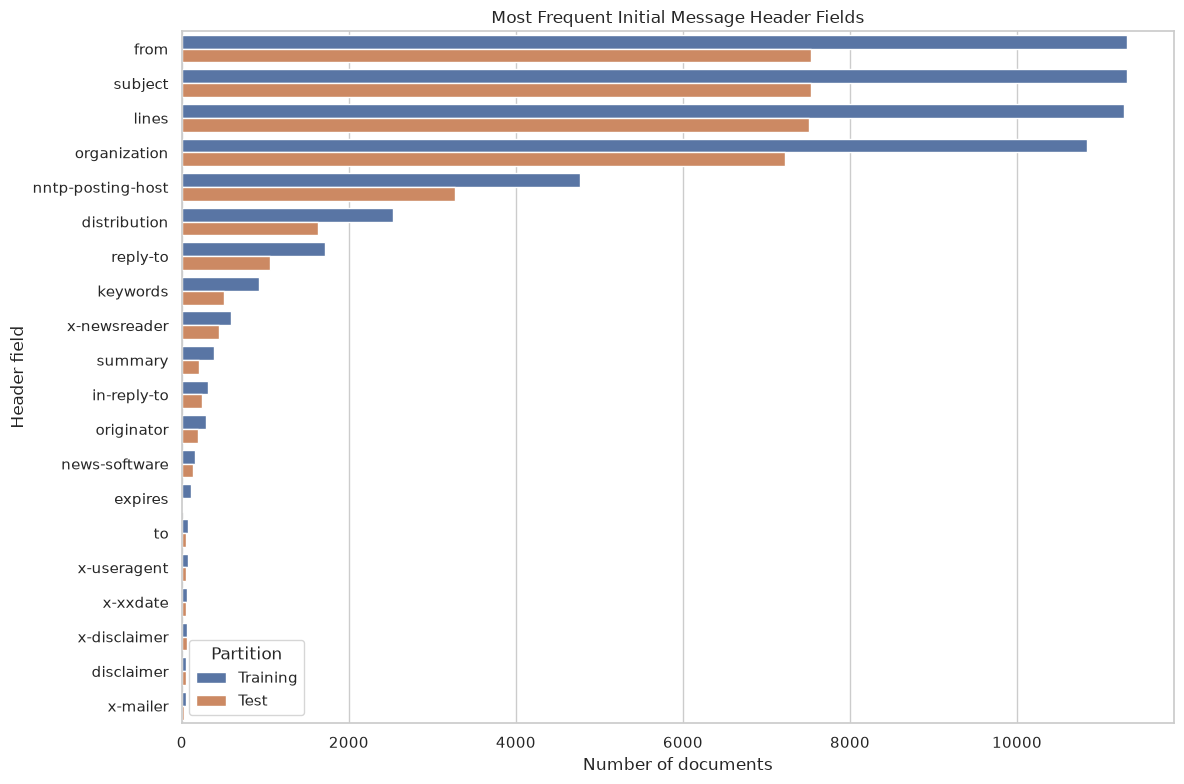

In [150]:
header_plot_data = (
    header_frequency[["Training", "Test"]]
    .head(20)
    .reset_index()
    .melt(
        id_vars="header_fields",
        var_name="Partition",
        value_name="Documents",
    )
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=header_plot_data,
    x="Documents",
    y="header_fields",
    hue="Partition",
)

plt.title("Most Frequent Initial Message Header Fields")
plt.xlabel("Number of documents")
plt.ylabel("Header field")
plt.legend(title="Partition")
plt.tight_layout()
plt.show()

### Initial header-field findings

The initial message headers exhibit a consistent structure across the training and test partitions.

The `From` and `Subject` fields occur in every document. The `Lines` field is present in approximately 99.6% of documents, while `Organization` occurs in approximately 95.8%. Other fields, including `NNTP-Posting-Host`, `Distribution` and `Reply-To`, are less consistently available.

The header inventory identified 112 distinct field names, indicating variation in metadata structure despite the high prevalence of several common fields.

Sender identities, organisational affiliations, posting hosts and other communication-related fields may allow a classifier to associate particular contributors or infrastructure with specific target categories. Such associations may not generalise to documents from different contributors or communication environments.

The `Subject` field requires separate treatment because it may contain legitimate information about the discussion topic. It should not automatically be treated as irrelevant metadata.

The findings support separating the initial message header from the message body during Data Preparation. The original documents will remain unchanged, allowing alternative text representations to be constructed and evaluated consistently.

## Explicit target-label leakage investigation

The 20 Newsgroups dataset assigns each document to one of 20 target categories. Some archived messages may retain the original `Newsgroups:` field, which can explicitly identify the category to which a document belongs.

If such information is included in model input, a classifier may learn to reproduce the category identifier instead of learning generalisable characteristics of the message content.

This section investigates whether `Newsgroups:` fields occur in the documents, whether their values match the assigned target category, and whether the fields appear in quoted correspondence.

The search covers the full document rather than only the initial header because forwarded and quoted messages may preserve earlier message metadata.

### Searching for explicit category metadata

This analysis searches the full document text for `Newsgroups` fields and checks whether each field value contains the assigned target category. It also records whether the matching line is quoted.

Searching beyond the initial header matters because forwarded and quoted messages can preserve earlier headers inside the body.

In [151]:
def extract_newsgroups_fields(
    text: str,
    target_label: str,
) -> list[dict[str, str | bool]]:
    """Extract Newsgroups fields and identify target-label matches."""

    pattern = re.compile(
        r"^\s*(?P<quotes>(?:>\s*)*)Newsgroups\s*:\s*(?P<value>.*?)\s*$",
        flags=re.IGNORECASE | re.MULTILINE,
    )

    matches = []

    for match in pattern.finditer(text):
        value = match.group("value").strip()

        target_pattern = (
            rf"(?<![\w.-]){re.escape(target_label)}(?![\w.-])"
        )

        matches.append({
            "value": value,
            "quoted": bool(match.group("quotes").strip()),
            "matches_target": bool(
                re.search(target_pattern, value, flags=re.IGNORECASE)
            ),
        })

    return matches


leakage_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        matches = extract_newsgroups_fields(
            text=document["text"],
            target_label=document["label_name"],
        )

        leakage_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "newsgroups_fields": matches,
            "field_count": len(matches),
            "contains_newsgroups": len(matches) > 0,
            "contains_target_match": any(
                item["matches_target"] for item in matches
            ),
            "contains_quoted_newsgroups": any(
                item["quoted"] for item in matches
            ),
            "contains_quoted_target_match": any(
                item["quoted"] and item["matches_target"]
                for item in matches
            ),
        })

leakage_data = pd.DataFrame(leakage_results)

display(
    leakage_data[
        [
            "Partition",
            "document_id",
            "label_name",
            "field_count",
            "contains_newsgroups",
            "contains_target_match",
            "contains_quoted_newsgroups",
            "contains_quoted_target_match",
        ]
    ].head()
)

,Partition,document_id,label_name,field_count,contains_newsgroups,contains_target_match,contains_quoted_newsgroups,contains_quoted_target_match
0,Training,train_000000,rec.sport.baseball,0,False,False,False,False
1,Training,train_000001,comp.sys.mac.hardware,0,False,False,False,False
2,Training,train_000002,sci.crypt,0,False,False,False,False
3,Training,train_000003,comp.sys.mac.hardware,0,False,False,False,False
4,Training,train_000004,alt.atheism,0,False,False,False,False


In [152]:
leakage_summary = (
    leakage_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_Newsgroups=(
            "contains_newsgroups",
            "sum",
        ),
        Documents_with_target_match=(
            "contains_target_match",
            "sum",
        ),
        Documents_with_quoted_Newsgroups=(
            "contains_quoted_newsgroups",
            "sum",
        ),
        Documents_with_quoted_target_match=(
            "contains_quoted_target_match",
            "sum",
        ),
        Total_Newsgroups_fields=("field_count", "sum"),
    )
)

count_columns = [
    "Documents_with_Newsgroups",
    "Documents_with_target_match",
    "Documents_with_quoted_Newsgroups",
    "Documents_with_quoted_target_match",
]

for column in count_columns:
    leakage_summary[f"{column} (%)"] = (
        leakage_summary[column]
        / leakage_summary["Documents"]
        * 100
    )

display(leakage_summary.round(2))

,Documents,Documents_with_Newsgroups,Documents_with_target_match,Documents_with_quoted_Newsgroups,Documents_with_quoted_target_match,Total_Newsgroups_fields,Documents_with_Newsgroups (%),Documents_with_target_match (%),Documents_with_quoted_Newsgroups (%),Documents_with_quoted_target_match (%)
Partition,,,,,,,,,,
Test,7532,48,39,22,20,55,0.64,0.52,0.29,0.27
Training,11314,37,28,14,12,42,0.33,0.25,0.12,0.11


In [153]:
target_match_examples = leakage_data[
    leakage_data["contains_target_match"]
].copy()

print(
    "Documents containing a Newsgroups field matching "
    "their assigned target label:",
    len(target_match_examples),
)

display(
    target_match_examples[
        [
            "Partition",
            "document_id",
            "label_name",
            "newsgroups_fields",
        ]
    ].head(10)
)

Documents containing a Newsgroups field matching their assigned target label: 67


,Partition,document_id,label_name,newsgroups_fields
308,Training,train_000308,misc.forsale,"[{'value': 'rec.audio,misc.forsale', 'quoted': False, 'matches_target': True}]"
1075,Training,train_001075,rec.sport.hockey,"[{'value': 'rec.sport.hockey', 'quoted': True, 'matches_target': True}]"
1506,Training,train_001506,talk.politics.guns,"[{'value': 'talk.politics.guns,ou.politics', 'quoted': True, 'matches_target': True}]"
1671,Training,train_001671,comp.graphics,"[{'value': 'comp.graphics', 'quoted': False, 'matches_target': True}]"
1839,Training,train_001839,talk.politics.misc,"[{'value': 'alt.activism,alt.conspiracy,talk.politics.misc,misc.legal', 'quoted': False, 'matches_target': True}]"
1878,Training,train_001878,comp.windows.x,"[{'value': 'comp.windows.x', 'quoted': True, 'matches_target': True}]"
1912,Training,train_001912,talk.politics.guns,"[{'value': 'talk.politics.guns', 'quoted': True, 'matches_target': True}]"
1934,Training,train_001934,rec.motorcycles,"[{'value': 'rec.motorcycles', 'quoted': False, 'matches_target': True}]"
2149,Training,train_002149,talk.politics.guns,"[{'value': 'talk.politics.guns', 'quoted': False, 'matches_target': True}]"
2307,Training,train_002307,rec.autos,"[{'value': 'rec.autos,rec.autos.vw', 'quoted': False, 'matches_target': True}, {'value': 'rec.autos,rec.autos.vw', '..."


In [154]:
def display_newsgroups_examples(
    leakage_data: pd.DataFrame,
    datasets: dict[str, pd.DataFrame],
    number_of_documents: int = 5,
) -> None:
    """Display matching Newsgroups fields with document context."""

    examples = leakage_data.loc[
        leakage_data["contains_target_match"]
    ].head(number_of_documents)

    # Build document lookups for both original partitions.
    text_lookup = {
        partition: data.set_index("document_id")["text"].to_dict()
        for partition, data in datasets.items()
    }

    for _, document in examples.iterrows():
        partition = document["Partition"]
        document_id = document["document_id"]
        target_label = document["label_name"]

        text = text_lookup[partition][document_id]
        lines = text.splitlines()

        print("=" * 90)
        print("Partition:", partition)
        print("Document:", document_id)
        print("Assigned topic:", target_label)

        target_pattern = (
            rf"(?<![\w.-]){re.escape(target_label)}(?![\w.-])"
        )

        for index, line in enumerate(lines):
            match = re.match(
                r"^\s*(?:>\s*)*Newsgroups\s*:\s*(.*)",
                line,
                flags=re.IGNORECASE,
            )

            if match and re.search(
                target_pattern,
                match.group(1),
                flags=re.IGNORECASE,
            ):
                start = max(0, index - 2)
                end = min(len(lines), index + 3)

                print("\nMatching Newsgroups field:")
                print("Quoted:", bool(re.match(r"^\s*>", line)))

                print("\nContext:")

                for context_line in lines[start:end]:
                    print(context_line)


display_newsgroups_examples(
    leakage_data=leakage_data,
    datasets=datasets,
    number_of_documents=5,
)

Partition: Training
Document: train_000308
Assigned topic: misc.forsale

Matching Newsgroups field:
Quoted: False

Context:


Newsgroups: rec.audio,misc.forsale
Distribution: na
Subject: Forsale: Sony D-22 diskman
Partition: Training
Document: train_001075
Assigned topic: rec.sport.hockey

Matching Newsgroups field:
Quoted: True

Context:

>Post: 51240 of 51243
>Newsgroups: rec.sport.hockey
>From: maynard@ramsey.cs.laurentian.ca (Roger Maynard)
>Subject: Re: Plus minus stat
Partition: Training
Document: train_001506
Assigned topic: talk.politics.guns

Matching Newsgroups field:
Quoted: True

Context:
Here'a a copy, cdt:
------------------------------------------------------------------------
>Newsgroups: talk.politics.guns,ou.politics
>Path: dg-rtp!psinntp!uunet!sun-barr!ames!haven.umd.edu!darwin.sura.net!wupost!csus.edu!netcom.com!mvp
>From: mvp@netcom.com (Mike Van Pelt)
Partition: Training
Document: train_001671
Assigned topic: comp.graphics

Matching Newsgroups field:
Quoted: False

### Explicit target-label references in Newsgroups fields

The investigation identified 67 documents containing a `Newsgroups:` field whose value matched the document's assigned target category.

Of these documents, 28 occur in the training partition and 39 occur in the test partition. Matching fields are not restricted to the initial message header: some appear in quoted correspondence or forwarded message content.

This distinction is important because removing only the initial message header would not necessarily eliminate every explicit category identifier. Similarly, removing only lines beginning with a quotation marker would not capture every forwarded or embedded message header.

Although the affected documents represent a small proportion of the dataset, explicit target-category identifiers could provide direct classification shortcuts if retained in model input.

The findings justify investigating structural metadata throughout the document rather than relying exclusively on initial-header removal.

The original text and assigned labels remain unchanged. Any metadata removal will be implemented as a separate, reproducible preparation operation.

### Searching for target names outside explicit metadata

The next analysis looks for occurrences of each document's assigned category name throughout its text, classifies the surrounding line as a `Newsgroups` field or another context, and records whether it is quoted.

A match is a signal for inspection, not automatic proof of leakage.

In [156]:
def find_target_label_occurrences(
    text: str,
    target_label: str,
) -> list[dict[str, str]]:
    """Find occurrences of a document's target label in its text."""

    target_pattern = re.compile(
        rf"(?<![\w.-]){re.escape(target_label)}(?![\w.-])",
        flags=re.IGNORECASE,
    )

    occurrences = []

    for line_number, line in enumerate(text.splitlines(), start=1):
        matches = list(target_pattern.finditer(line))

        if not matches:
            continue

        is_newsgroups = bool(
            re.match(
                r"^\s*(?:>\s*)*Newsgroups\s*:",
                line,
                flags=re.IGNORECASE,
            )
        )

        is_quoted = bool(re.match(r"^\s*>", line))

        if is_newsgroups and is_quoted:
            context_type = "quoted_newsgroups"
        elif is_newsgroups:
            context_type = "unquoted_newsgroups"
        elif is_quoted:
            context_type = "quoted_non_newsgroups"
        else:
            context_type = "unquoted_non_newsgroups"

        for match in matches:
            occurrences.append({
                "line_number": str(line_number),
                "matched_text": match.group(),
                "line": line.strip(),
                "context_type": context_type,
            })

    return occurrences


target_reference_results = []

for split_name, data in datasets.items():
    for _, document in data.iterrows():
        occurrences = find_target_label_occurrences(
            text=document["text"],
            target_label=document["label_name"],
        )

        target_reference_results.append({
            "Partition": split_name,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "occurrences": occurrences,
            "occurrence_count": len(occurrences),
            "contains_target_reference": len(occurrences) > 0,
            "contains_non_newsgroups_reference": any(
                item["context_type"] != "unquoted_newsgroups"
                and item["context_type"] != "quoted_newsgroups"
                for item in occurrences
            ),
        })

target_reference_data = pd.DataFrame(target_reference_results)

display(
    target_reference_data[
        [
            "Partition",
            "document_id",
            "label_name",
            "occurrence_count",
            "contains_target_reference",
            "contains_non_newsgroups_reference",
        ]
    ].head()
)

,Partition,document_id,label_name,occurrence_count,contains_target_reference,contains_non_newsgroups_reference
0,Training,train_000000,rec.sport.baseball,0,False,False
1,Training,train_000001,comp.sys.mac.hardware,0,False,False
2,Training,train_000002,sci.crypt,5,True,True
3,Training,train_000003,comp.sys.mac.hardware,0,False,False
4,Training,train_000004,alt.atheism,0,False,False


In [157]:
target_reference_summary = (
    target_reference_data
    .groupby("Partition")
    .agg(
        Documents=("document_id", "count"),
        Documents_with_target_reference=(
            "contains_target_reference",
            "sum",
        ),
        Documents_with_non_newsgroups_reference=(
            "contains_non_newsgroups_reference",
            "sum",
        ),
        Total_target_label_occurrences=(
            "occurrence_count",
            "sum",
        ),
    )
)

for column in [
    "Documents_with_target_reference",
    "Documents_with_non_newsgroups_reference",
]:
    target_reference_summary[f"{column} (%)"] = (
        target_reference_summary[column]
        / target_reference_summary["Documents"]
        * 100
    )

display(target_reference_summary.round(2))

,Documents,Documents_with_target_reference,Documents_with_non_newsgroups_reference,Total_target_label_occurrences,Documents_with_target_reference (%),Documents_with_non_newsgroups_reference (%)
Partition,,,,,,
Test,7532,248,216,307,3.29,2.87
Training,11314,317,291,500,2.80,2.57


In [158]:
context_results = []

for _, document in target_reference_data.iterrows():
    for occurrence in document["occurrences"]:
        context_results.append({
            "Partition": document["Partition"],
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            "context_type": occurrence["context_type"],
            "line_number": int(occurrence["line_number"]),
            "line": occurrence["line"],
        })

target_context_data = pd.DataFrame(context_results)

if not target_context_data.empty:
    context_summary = (
        target_context_data
        .groupby(["context_type", "Partition"])
        .agg(
            Occurrences=("line_number", "count"),
            Documents=("document_id", "nunique"),
        )
        .reset_index()
    )

    display(context_summary)
else:
    print("No target-label references were detected.")

,context_type,Partition,Occurrences,Documents
0,quoted_newsgroups,Test,20,20
1,quoted_newsgroups,Training,13,12
2,quoted_non_newsgroups,Test,46,41
3,quoted_non_newsgroups,Training,56,49
4,unquoted_newsgroups,Test,26,19
5,unquoted_newsgroups,Training,20,16
6,unquoted_non_newsgroups,Test,215,176
7,unquoted_non_newsgroups,Training,411,253


In [159]:
non_newsgroups_examples = target_context_data[
    ~target_context_data["context_type"].isin([
        "quoted_newsgroups",
        "unquoted_newsgroups",
    ])
].drop_duplicates(
    subset=["Partition", "document_id", "line_number"]
)

print(
    "Documents with target-label references outside Newsgroups fields:",
    non_newsgroups_examples["document_id"].nunique(),
)

for _, occurrence in non_newsgroups_examples.head(15).iterrows():
    print("=" * 90)
    print("Partition:", occurrence["Partition"])
    print("Document:", occurrence["document_id"])
    print("Assigned topic:", occurrence["label_name"])
    print("Context:", occurrence["context_type"])
    print("Line number:", occurrence["line_number"])
    print("Text:", occurrence["line"])

Documents with target-label references outside Newsgroups fields: 507
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 8
Text: Summary: Part 10 of 10 of the sci.crypt FAQ, References.
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 18
Text: FAQ for sci.crypt, part 10: References
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 20
Text: This is the tenth of ten parts of the sci.crypt FAQ. The parts are
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 27
Text: FAQ is posted to the newsgroups sci.crypt, sci.answers, and news.answers
Partition: Training
Document: train_000002
Assigned topic: sci.crypt
Context: unquoted_non_newsgroups
Line number: 330
Text: There are other newsgroups which a sci.crypt reader might want also to
Par

### Target-label references throughout document text

Target-category identifiers are not restricted to explicit `Newsgroups:` fields. The investigation also identified occurrences of the assigned target label elsewhere in document text.

Such references occur in approximately 2.80% of training documents and 3.29% of test documents. Many appear in ordinary prose, subject headers, FAQs and quoted discussions rather than explicit category metadata.

Manual inspection demonstrates that these occurrences do not all constitute target leakage. For example, a discussion about cryptography may legitimately refer to `sci.crypt`, while a message discussing space-related topics may mention `sci.space`.

Automatically removing every occurrence of a target-category name would therefore be inappropriate. It could remove meaningful topical information, alter the original document content and introduce unnecessary preprocessing assumptions.

**Implications for data preparation**

- Preserve the original raw documents as an immutable source.
- Identify and handle structural metadata separately from ordinary message content.
- Avoid indiscriminate removal of target-category names from prose.
- Evaluate subject information through controlled comparisons.
- Apply identical preprocessing rules to training, validation and test data.
- Assess potential shortcut learning through empirical model evaluation.

These findings identify possible sources of shortcut learning but do not establish that they cause inflated classification performance. Their practical impact must be assessed through controlled experiments.

## Detailed metadata profiling

The previous analyses identified message-header fields that may contain information associated with target categories.

This section examines selected fields in greater detail. The analysis considers:

- **Completeness:** how frequently each field contains a non-empty value.
- **Value diversity:** the number and distribution of distinct values within each field.
- **Observed values:** examples of frequently occurring metadata values.
- **Target association:** the relationship between metadata values and assigned target categories.
- **Class concentration:** whether repeated metadata values are disproportionately associated with particular categories.

The initial-header extraction is used to profile the selected fields. Where a field has no extracted values, its absence is checked against the original initial headers rather than assuming that the extraction result is correct.

The association and class-concentration analyses use the training partition. This avoids using the official test labels to guide the identification of potentially useful or problematic metadata features.

### Building and profiling header records

Selected initial-header fields are extracted into a separate table linked to each document's identifier, partition and target label.

The following analyses measure field completeness and distinct-value counts, inspect common values, and validate fields that were not detected. This structured view assesses metadata independently of message bodies while leaving original documents untouched.

In [160]:
HEADER_FIELDS_TO_PROFILE = [
    "from",
    "subject",
    "organization",
    "nntp-posting-host",
    "summary",
    "keywords",
    "distribution",
    "newsgroups",
    "message-id",
    "date",
    "path",
    "lines",
    "references",
    "reply-to",
    "sender",
]


def extract_initial_header_values(text: str) -> dict[str, str]:
    """Extract selected values from a document's initial header."""

    header_block = re.split(
        r"\r?\n[ \t]*\r?\n",
        text,
        maxsplit=1,
    )[0]

    parsed_fields = {}
    current_field = None

    for line in header_block.splitlines():
        if line[:1] in (" ", "\t") and current_field is not None:
            parsed_fields[current_field] += " " + line.strip()
            continue

        match = re.match(
            r"^([A-Za-z0-9-]+):\s*(.*)$",
            line,
        )

        if match:
            current_field = match.group(1).casefold()
            value = match.group(2).strip()

            parsed_fields.setdefault(current_field, value)

        else:
            current_field = None

    return {
        field: parsed_fields.get(field, "")
        for field in HEADER_FIELDS_TO_PROFILE
    }


header_records = []

for partition, data in datasets.items():
    for _, document in data.iterrows():
        header_values = extract_initial_header_values(
            document["text"]
        )

        header_records.append({
            "Partition": partition,
            "document_id": document["document_id"],
            "label_name": document["label_name"],
            **header_values,
        })

message_headers = pd.DataFrame(header_records)

print("Extracted header records:", len(message_headers))
print("Header fields profiled:", len(HEADER_FIELDS_TO_PROFILE))

display(message_headers.head())

Extracted header records: 18846
Header fields profiled: 15


,Partition,document_id,label_name,from,subject,organization,nntp-posting-host,summary,keywords,distribution,newsgroups,message-id,date,path,lines,references,reply-to,sender
0,Training,train_000000,rec.sport.baseball,cubbie@garnet.berkeley.edu ( ),Re: Cubs behind Marlins? How?,"University of California, Berkeley",garnet.berkeley.edu,,,,,,,,12,,,
1,Training,train_000001,comp.sys.mac.hardware,gnelson@pion.rutgers.edu (Gregory Nelson),Thanks Apple: Free Ethernet on my C610!,"Rutgers Univ., New Brunswick, N.J.",,,,,,,,,26,,,
2,Training,train_000002,sci.crypt,crypt-comments@math.ncsu.edu,Cryptography FAQ 10/10 - References,The Crypt Cabal,pad-thai.aktis.com,"Part 10 of 10 of the sci.crypt FAQ, References. History and classical methods. Modern methods. Survey and reference ...",,,,,,,333,,crypt-comments@math.ncsu.edu,
3,Training,train_000003,comp.sys.mac.hardware,(),Re: Quadra SCSI Problems???,Apple Computer Inc.,,,,,,,,,28,,,
4,Training,train_000004,alt.atheism,keith@cco.caltech.edu (Keith Allan Schneider),Re: <Political Atheists?,"California Institute of Technology, Pasadena",lloyd.caltech.edu,,,,,,,,14,,,


In [161]:
header_completeness = []

for field in HEADER_FIELDS_TO_PROFILE:
    for partition, data in message_headers.groupby("Partition"):
        present = data[field].fillna("").str.strip().ne("")

        header_completeness.append({
            "Header field": field,
            "Partition": partition,
            "Documents": len(data),
            "Documents with value": int(present.sum()),
            "Missing": int((~present).sum()),
            "Present (%)": present.mean() * 100,
        })

header_completeness = pd.DataFrame(header_completeness)

header_completeness_pivot = header_completeness.pivot(
    index="Header field",
    columns="Partition",
    values="Present (%)",
)

header_completeness_pivot.columns.name = None

display(header_completeness_pivot.round(2))

,Test,Training
Header field,,
date,0.00,0.00
distribution,21.57,22.39
from,100.00,100.00
keywords,6.60,8.08
lines,99.67,99.61
message-id,0.00,0.00
newsgroups,0.00,0.00
nntp-posting-host,43.37,42.10
organization,95.90,95.78


In [162]:
header_diversity = []

for field in HEADER_FIELDS_TO_PROFILE:
    for partition, data in message_headers.groupby("Partition"):
        values = (
            data[field]
            .fillna("")
            .str.strip()
        )

        nonempty_values = values[values.ne("")]
        value_counts = nonempty_values.value_counts()

        header_diversity.append({
            "Header field": field,
            "Partition": partition,
            "Documents with value": len(nonempty_values),
            "Distinct values": nonempty_values.nunique(),
            "Distinct value ratio (%)": (
                nonempty_values.nunique()
                / len(nonempty_values)
                * 100
                if len(nonempty_values) > 0
                else 0
            ),
            "Most frequent value (%)": (
                value_counts.iloc[0] / len(nonempty_values) * 100
                if len(nonempty_values) > 0
                else 0
            ),
        })

header_diversity = pd.DataFrame(header_diversity)

display(
    header_diversity
    .sort_values(
        ["Header field", "Partition"]
    )
    .round(2)
)

,Header field,Partition,Documents with value,Distinct values,Distinct value ratio (%),Most frequent value (%)
18,date,Test,0,0,0.00,0.00
19,date,Training,0,0,0.00,0.00
12,distribution,Test,1625,74,4.55,43.51
13,distribution,Training,2533,104,4.11,37.19
0,from,Test,7532,4249,56.41,0.68
1,from,Training,11314,5835,51.57,0.65
10,keywords,Test,497,365,73.44,2.62
11,keywords,Training,914,585,64.00,2.41
22,lines,Test,7507,315,4.20,3.30
23,lines,Training,11270,378,3.35,3.29


In [163]:
FIELDS_FOR_VALUE_INSPECTION = [
    "subject",
    "organization",
    "nntp-posting-host",
    "distribution",
    "summary",
    "keywords",
]

for field in FIELDS_FOR_VALUE_INSPECTION:
    print("\n" + "=" * 90)
    print(f"HEADER FIELD: {field.upper()}")

    for partition, data in message_headers.groupby("Partition"):
        values = (
            data[field]
            .fillna("")
            .str.strip()
        )

        values = values[values.ne("")]

        print(f"\n{partition} — Top 5 values")

        if values.empty:
            print("No values found.")
            continue

        top_values = values.value_counts().head(5)

        for value, count in top_values.items():
            percentage = count / len(values) * 100
            display_value = (
                value[:120] + "..."
                if len(value) > 120
                else value
            )

            print(
                f"{count:>5} ({percentage:>5.2f}%): "
                f"{display_value}"
            )


HEADER FIELD: SUBJECT

Test — Top 5 values
   52 ( 0.69%): Re: Challenge to Microsoft supporters.
   52 ( 0.69%): Re: ATF BURNS DIVIDIAN RANCH! NO SURVIVORS!!!
   51 ( 0.68%): Re: Europe vs. Muslim Bosnians
   50 ( 0.66%): Re: New Study Out On Gay Percentage
   36 ( 0.48%): Re: How to the disks copy protected.

Training — Top 5 values
   76 ( 0.67%): Re: Once tapped, your code is no good any more.
   52 ( 0.46%): Re: Is MSG sensitivity superstition?
   49 ( 0.43%): Re: After 2000 years, can we say that Christian Morality is
   46 ( 0.41%): Re: WARNING.....(please read)...
   43 ( 0.38%): Re: <Political Atheists?

HEADER FIELD: ORGANIZATION

Test — Top 5 values
   84 ( 1.16%): University of Illinois at Urbana
   82 ( 1.14%): AT&T
   53 ( 0.73%): NETCOM On-line Communication Services (408 241-9760 guest)
   50 ( 0.69%): Case Western Reserve University, Cleveland, OH (USA)
   43 ( 0.60%): University of Virginia

Training — Top 5 values
  125 ( 1.15%): University of Illinois at Urbana
   

In [ ]:
FIELDS_REQUIRING_VALIDATION = [
    "date",
    "message-id",
    "newsgroups",
    "path",
    "references",
    "sender",
]

for partition, data in datasets.items():
    print("\n" + "=" * 90)
    print(f"PARTITION: {partition}")

    for field in FIELDS_REQUIRING_VALIDATION:
        pattern = re.compile(
            rf"^\s*{re.escape(field)}\s*:",
            flags=re.IGNORECASE,
        )

        matching_examples = []

        for _, document in data.iterrows():
            initial_header = re.split(
                r"\r?\n[ \t]*\r?\n",
                document["text"],
                maxsplit=1,
            )[0]

            matches = [
                line.strip()
                for line in initial_header.splitlines()
                if pattern.match(line)
            ]

            if matches:
                matching_examples.append(
                    (document["document_id"], matches[0])
                )

            if len(matching_examples) >= 3:
                break

        print(f"\n{field.upper()}")

        if matching_examples:
            for document_id, value in matching_examples:
                print(f"{document_id}: {value[:180]}")
        else:
            print("No matching field found in inspected initial headers.")


PARTITION: Training


### Metadata completeness and diversity findings

The selected header fields differ considerably in their availability and value diversity.

The `From` and `Subject` fields are present in every document. `Organization` is available in approximately 95.8% of documents, while `NNTP-Posting-Host` is present in approximately 42–43%. Other fields, such as `Keywords`, `Summary` and `Reply-To`, are substantially less complete.

The diversity analysis also reveals that many fields contain a large number of distinct values. Sender identities, subject lines and organisational affiliations are particularly variable. This is important because metadata can contain high-cardinality information that may be associated with individual contributors, discussions or target categories.

The inspection of frequent values demonstrates that metadata fields have different meanings. Some describe communication infrastructure or the identity of contributors, while others contain information about the actual subject matter.

The validation checks found no matching `Date`, `Message-ID`, `Newsgroups`, `Path`, `References` or `Sender` fields in the initial headers. These zero-value results are therefore consistent with the inspected source documents rather than being assumed to indicate missing values caused by extraction failure.

The findings support treating metadata fields according to their meaning and potential modelling implications rather than applying one indiscriminate removal rule to all header information.

In [115]:
CATEGORICAL_HEADER_FIELDS = [
    "from",
    "subject",
    "organization",
    "nntp-posting-host",
    "summary",
    "keywords",
    "distribution",
    "reply-to",
]

training_headers = message_headers.loc[
    message_headers["Partition"] == "Training"
].copy()

association_results = []

for field in CATEGORICAL_HEADER_FIELDS:
    values = (
        training_headers[field]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    present = values.ne("")
    targets = training_headers["label_name"]

    # Association between field availability and target class.
    presence_ami = adjusted_mutual_info_score(
        targets,
        present.astype(str),
    )

    # Association between actual field values and target class,
    # considering only documents in which the field is present.
    if present.sum() > 1 and values[present].nunique() > 1:
        value_ami = adjusted_mutual_info_score(
            targets[present],
            values[present],
        )
    else:
        value_ami = np.nan

    association_results.append({
        "Header field": field,
        "Documents with value": int(present.sum()),
        "Documents without value": int((~present).sum()),
        "Distinct values": int(values[present].nunique()),
        "Presence AMI": presence_ami,
        "Value AMI (present documents)": value_ami,
    })

header_associations = (
    pd.DataFrame(association_results)
    .sort_values(
        "Value AMI (present documents)",
        ascending=False,
        na_position="last",
    )
    .reset_index(drop=True)
)

display(header_associations.round(4))

,Header field,Documents with value,Documents without value,Distinct values,Presence AMI,Value AMI (present documents)
0,reply-to,1720,9594,793,0.0049,0.3642
1,keywords,914,10400,582,0.0073,0.2742
2,subject,11314,0,6558,0.0000,0.2407
3,nntp-posting-host,4763,6551,1822,0.0183,0.2381
4,from,11314,0,5817,0.0000,0.2379
5,organization,10837,477,2989,0.0079,0.2103
6,distribution,2533,8781,102,0.0146,0.1421
7,summary,391,10923,368,0.0035,0.0546


In [116]:
MIN_VALUE_SUPPORT = 5

FIELDS_FOR_CLASS_ANALYSIS = [
    "reply-to",
    "keywords",
    "subject",
    "nntp-posting-host",
    "from",
    "organization",
    "distribution",
    "summary",
]

header_value_profiles = []

for field in FIELDS_FOR_CLASS_ANALYSIS:
    field_data = training_headers[
        ["document_id", "label_name", field]
    ].copy()

    field_data[field] = (
        field_data[field]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    field_data = field_data[
        field_data[field].ne("")
    ]

    if field_data.empty:
        continue

    value_class_counts = (
        field_data
        .groupby([field, "label_name"])
        .size()
        .unstack(fill_value=0)
    )

    value_totals = value_class_counts.sum(axis=1)

    sufficiently_frequent = value_totals[
        value_totals >= MIN_VALUE_SUPPORT
    ].index

    value_class_counts = value_class_counts.loc[
        sufficiently_frequent
    ]

    for value, class_counts in value_class_counts.iterrows():
        total = int(class_counts.sum())
        dominant_class = class_counts.idxmax()
        dominant_count = int(class_counts.max())

        header_value_profiles.append({
            "Header field": field,
            "Value": value,
            "Documents": total,
            "Dominant class": dominant_class,
            "Dominant class documents": dominant_count,
            "Dominant class share (%)": (
                dominant_count / total * 100
            ),
            "Classes represented": int(
                (class_counts > 0).sum()
            ),
        })

header_value_profiles = pd.DataFrame(
    header_value_profiles
)

print(
    "Header values meeting minimum support:",
    len(header_value_profiles),
)

display(
    header_value_profiles
    .sort_values(
        ["Header field", "Dominant class share (%)", "Documents"],
        ascending=[True, False, False],
    )
    .groupby("Header field", group_keys=False)
    .head(5)
    .round(2)
    .reset_index(drop=True)
)

Header values meeting minimum support: 1596


,Header field,Value,Documents,Dominant class,Dominant class documents,Dominant class share (%),Classes represented
0,distribution,sfnet,5,alt.atheism,5,100.00,1
1,distribution,sci,48,sci.space,46,95.83,2
2,distribution,tx,7,talk.politics.misc,6,85.71,2
3,distribution,rec,21,rec.motorcycles,14,66.67,4
4,distribution,ba,15,misc.forsale,10,66.67,4
5,from,sera@zuma.uucp (serdar argic),70,talk.politics.mideast,70,100.00,1
6,from,keith@cco.caltech.edu (keith allan schneider),52,alt.atheism,52,100.00,1
7,from,cramer@optilink.com (clayton cramer),30,talk.politics.misc,30,100.00,1
8,from,dbd@urartu.sdpa.org (david davidian),29,talk.politics.mideast,29,100.00,1
9,from,jake@bony1.bony.com (jake livni),28,talk.politics.mideast,28,100.00,1


In [117]:
strong_concentrations = header_value_profiles.loc[
    (header_value_profiles["Documents"] >= 10)
    & (
        header_value_profiles["Dominant class share (%)"]
        >= 80
    )
].copy()

strong_concentrations = strong_concentrations.sort_values(
    ["Header field", "Dominant class share (%)", "Documents"],
    ascending=[True, False, False],
)

print(
    "Values with at least 10 documents and 80% class concentration:",
    len(strong_concentrations),
)

display(
    strong_concentrations.round(2).reset_index(drop=True)
)

Values with at least 10 documents and 80% class concentration: 329


,Header field,Value,Documents,Dominant class,Dominant class documents,Dominant class share (%),Classes represented
0,distribution,sci,48,sci.space,46,95.83,2
1,from,sera@zuma.uucp (serdar argic),70,talk.politics.mideast,70,100.00,1
2,from,keith@cco.caltech.edu (keith allan schneider),52,alt.atheism,52,100.00,1
3,from,cramer@optilink.com (clayton cramer),30,talk.politics.misc,30,100.00,1
4,from,dbd@urartu.sdpa.org (david davidian),29,talk.politics.mideast,29,100.00,1
...,...,...,...,...,...,...,...
324,subject,re: what is zero db????,10,sci.electronics,10,100.00,1
325,subject,re: what to do with old 256k simms?,10,sci.electronics,10,100.00,1
326,subject,re: win nt - what is it???,10,comp.os.ms-windows.misc,10,100.00,1
327,subject,re: text of white house announcement and q&as on clipper chip encryption,44,sci.crypt,42,95.45,2


In [118]:
concentration_summary = (
    strong_concentrations
    .groupby("Header field")
    .agg(
        Concentrated_values=("Value", "count"),
        Documents_represented=("Documents", "sum"),
        Mean_class_concentration=(
            "Dominant class share (%)",
            "mean",
        ),
        Maximum_class_concentration=(
            "Dominant class share (%)",
            "max",
        ),
    )
)

field_document_counts = (
    training_headers[ FIELDS_FOR_CLASS_ANALYSIS ]
    .replace(r"^\s*$", np.nan, regex=True)
    .notna()
    .sum()
)

concentration_summary["Documents_with_field"] = (
    field_document_counts
)

concentration_summary["Documents_represented (%)"] = (
    concentration_summary["Documents_represented"]
    / concentration_summary["Documents_with_field"]
    * 100
)

concentration_summary = concentration_summary.sort_values(
    "Documents_represented (%)",
    ascending=False,
)

display(concentration_summary.round(2))

,Concentrated_values,Documents_represented,Mean_class_concentration,Maximum_class_concentration,Documents_with_field,Documents_represented (%)
Header field,,,,,,
reply-to,17,322,97.28,100.00,1720,18.72
subject,107,1861,99.87,100.00,11314,16.45
from,99,1684,95.75,100.00,11314,14.88
nntp-posting-host,33,600,95.43,100.00,4763,12.60
organization,68,1222,93.56,100.00,10837,11.28
keywords,4,62,100.00,100.00,914,6.78
distribution,1,48,95.83,95.83,2533,1.89


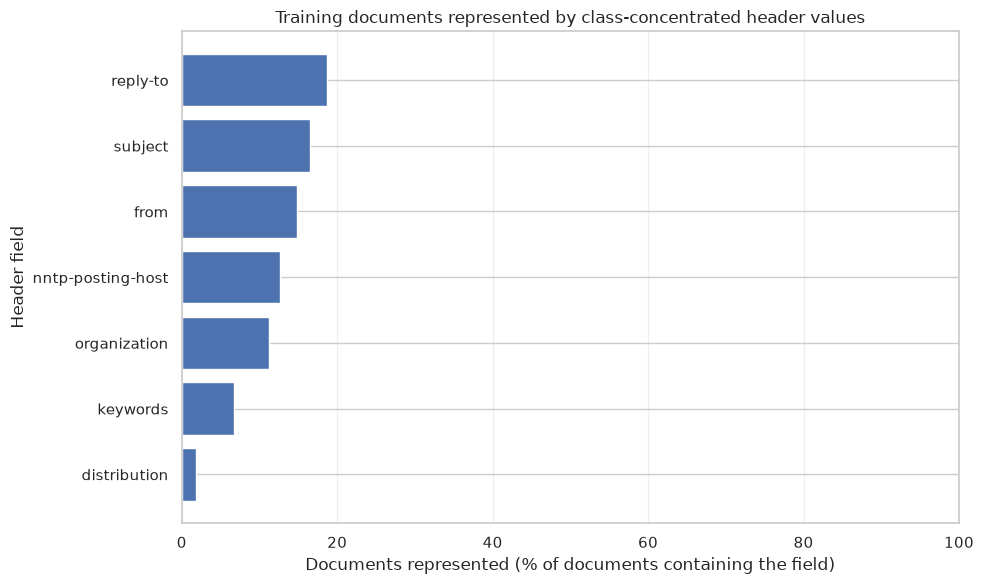

In [119]:
plot_data = concentration_summary.sort_values(
    "Documents_represented (%)",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_data.index,
    plot_data["Documents_represented (%)"],
)

ax.set_title(
    "Training documents represented by class-concentrated header values"
)
ax.set_xlabel(
    "Documents represented (% of documents containing the field)"
)
ax.set_ylabel("Header field")

ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Metadata associations and shortcut-learning risk

The metadata investigation identified associations between several header-field values and the target categories in the training partition.

Adjusted Mutual Information (AMI) was used to examine the relationship between individual metadata fields and the target labels. The strongest observed associations among the profiled values were:

| Header field | Value AMI |
|---|---:|
| `Reply-To` | 0.3642 |
| `Keywords` | 0.2742 |
| `Subject` | 0.2407 |
| `NNTP-Posting-Host` | 0.2381 |
| `From` | 0.2379 |
| `Organization` | 0.2103 |
| `Distribution` | 0.1421 |
| `Summary` | 0.0546 |

The presence or absence of these fields had substantially weaker associations with the target labels than their actual values. This suggests that the information contained in particular metadata values is more informative about the target categories than simply whether a field is available.

Further analysis identified repeated metadata values with strong class concentration. A total of 329 values met the specified minimum support of ten documents and dominant-class concentration of at least 80%.

Some sender addresses, posting hosts and organisational values were strongly concentrated in individual newsgroups. Such patterns may enable a classifier to learn contributor- or infrastructure-specific associations instead of relying primarily on generalisable topic-related language.

Subject information requires a different interpretation. Although repeated subject values can be strongly associated with particular categories, subjects often describe the actual discussion topic. Removing them without evaluation could discard useful information.

The AMI and concentration analyses are exploratory screening methods. They measure associations within the training data; they do not establish causality, prove information leakage or demonstrate that a model will achieve inflated performance.

**Data preparation decisions**

- Preserve the original raw documents without modification.
- Separate initial message headers from message bodies.
- Exclude author-identifying and infrastructure-related metadata from the primary modelling representation, including `From`, `Reply-To`, `Organization` and `NNTP-Posting-Host`.
- Exclude structural metadata such as `Distribution` and `Lines`.
- Retain extracted subject information separately for a controlled comparison against a body-only representation.
- Do not automatically remove target-category references from ordinary prose.
- Treat sparse fields such as `Keywords` and `Summary` as supplementary information rather than mandatory model inputs.
- Use training and validation data to evaluate preprocessing decisions, reserving the official test partition for final model evaluation.

This establishes a content-focused primary modelling strategy while preserving the ability to measure the contribution of potentially useful subject information independently.